# Model Comparison and Conclusions

This notebook compares the three models on the 17,903 test bookings, following the protocol in `03-Performance_metrics`. The primary metric is the Brier score. The results in `eval/` were produced by the shared scoring tool `LukeD/metrics/evaluate.py`, using the command in the README; this notebook reads them. Intervals are 95% cluster-bootstrap intervals, which resample each block of identical rows as one unit.

| Model | Author | Notebook |
| --- | --- | --- |
| Gradient boosted trees (XGBoost) | Thomas F | `04-XGBoost.ipynb` |
| Random forest | Luke D | `05-Random_forest.ipynb` |
| Logistic regression | Morgan L | `06-Logistic_regression.Rmd` |

In [1]:
import os
import numpy as np
import pandas as pd
from IPython.display import Image, display

MODELS = {"XGB_Thomas": "ThomasF", "RF_Luke": "LukeD", "Logit_Morgan": "MorganL"}

metrics = pd.read_csv(os.path.join("eval", "metrics.csv"))
pairwise = pd.read_csv(os.path.join("eval", "pairwise.csv"))

truth = pd.read_csv(os.path.join("..", "Data", "test_truth.csv"))
clean = pd.read_csv(os.path.join("..", "Data", "hotel_bookings_clean.csv"), keep_default_na=False, na_values=[""])
preds = {}
for name, folder in MODELS.items():
    p = pd.read_csv(os.path.join("..", folder, "test_preds.csv"))
    assert set(p.id) == set(truth.id), f"{name}: ids do not match the test set"
    preds[name] = truth[["id"]].merge(p, on="id").prediction.to_numpy()
y = truth.y.to_numpy()

## 1. Results

In [2]:
show = ["brier", "brier_skill", "log_loss", "roc_auc", "cal_slope", "accuracy", "mcc"]
m = metrics[metrics.metric.isin(show)].copy()
m["value"] = [f"{e:.4f} [{lo:.4f}, {hi:.4f}]" for e, lo, hi in zip(m.estimate, m.ci_low, m.ci_high)]
m.pivot(index="metric", columns="model", values="value").loc[show, list(MODELS)]

model,XGB_Thomas,RF_Luke,Logit_Morgan
metric,,,
brier,"0.1014 [0.0955, 0.1072]","0.1021 [0.0963, 0.1078]","0.1225 [0.1156, 0.1294]"
brier_skill,"0.5637 [0.5301, 0.5970]","0.5609 [0.5279, 0.5945]","0.4732 [0.4357, 0.5132]"
log_loss,"0.3109 [0.2943, 0.3274]","0.3158 [0.2992, 0.3323]","0.3804 [0.3601, 0.4001]"
roc_auc,"0.9304 [0.9210, 0.9391]","0.9287 [0.9189, 0.9377]","0.8932 [0.8791, 0.9068]"
cal_slope,"0.9781 [0.9289, 1.0296]","1.0526 [0.9942, 1.1139]","0.9055 [0.8530, 0.9600]"
accuracy,"0.8511 [0.8410, 0.8611]","0.8511 [0.8407, 0.8611]","0.8227 [0.8107, 0.8343]"
mcc,"0.6758 [0.6465, 0.7043]","0.6759 [0.6469, 0.7037]","0.6110 [0.5753, 0.6440]"


In [3]:
# paired Brier differences (first model minus second)
b = pairwise[pairwise.metric == "brier"]
pd.DataFrame({"comparison": b.model_a + " − " + b.model_b,
              "Brier difference [95% CI]": [f"{d:+.4f} [{lo:+.4f}, {hi:+.4f}]" for d, lo, hi in zip(b["diff"], b.ci_low, b.ci_high)]
              }).set_index("comparison")

,Brier difference [95% CI]
comparison,
RF_Luke − XGB_Thomas,"+0.0007 [-0.0005, +0.0019]"
RF_Luke − Logit_Morgan,"-0.0204 [-0.0248, -0.0159]"
XGB_Thomas − Logit_Morgan,"-0.0210 [-0.0253, -0.0166]"


* The two tree models are almost identical: Brier scores of 0.1014 (XGBoost) and 0.1021 (random forest), AUC 0.930 and 0.929, and 85.1% accuracy each. Their Brier difference of 0.0007 has an interval that includes zero.
* The logistic regression is clearly behind: Brier score 0.1225, AUC 0.893 and 82.3% accuracy. Its Brier score is about 0.02 higher than either tree model's, with intervals well away from zero.
* All three are close to calibrated. The logistic regression's calibration slope of 0.91 means its probabilities are slightly too extreme, and the random forest's 1.05 means they are slightly too cautious.

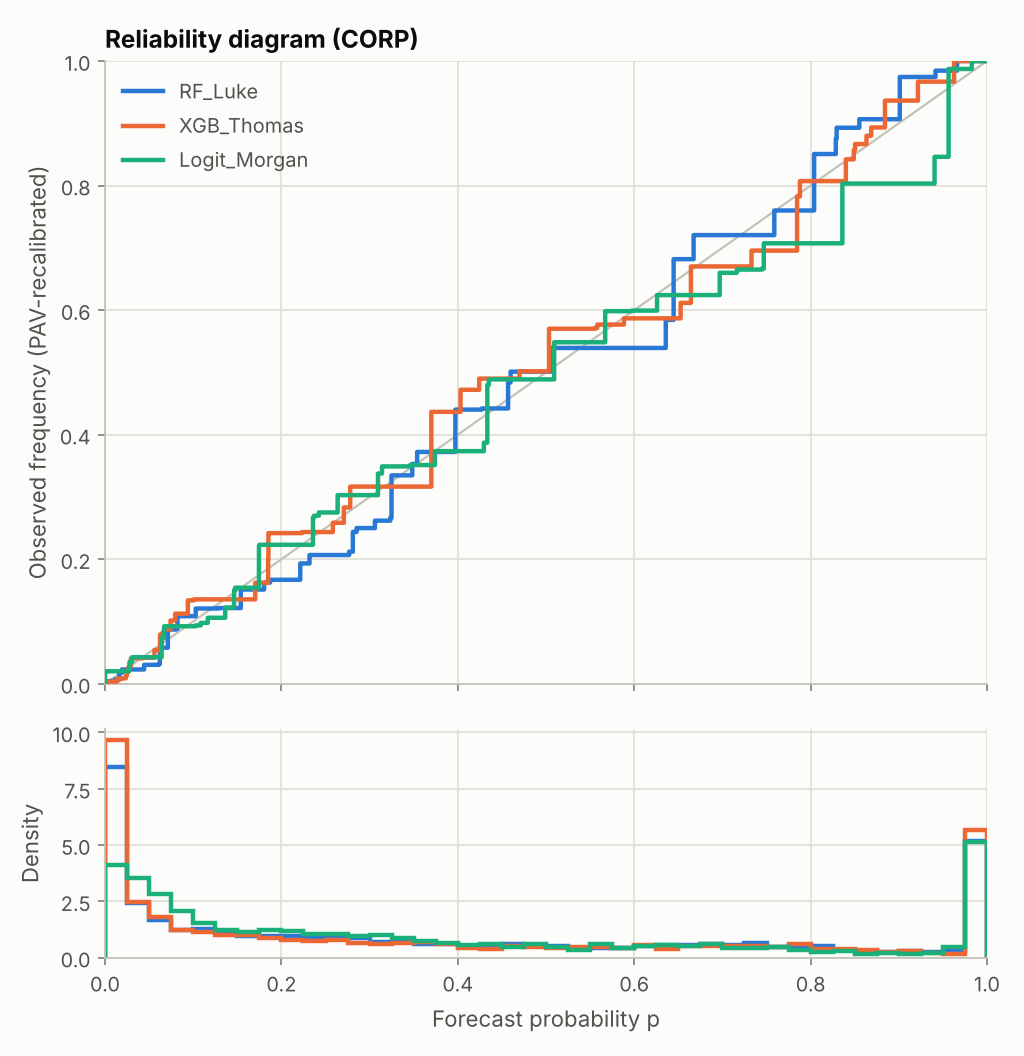

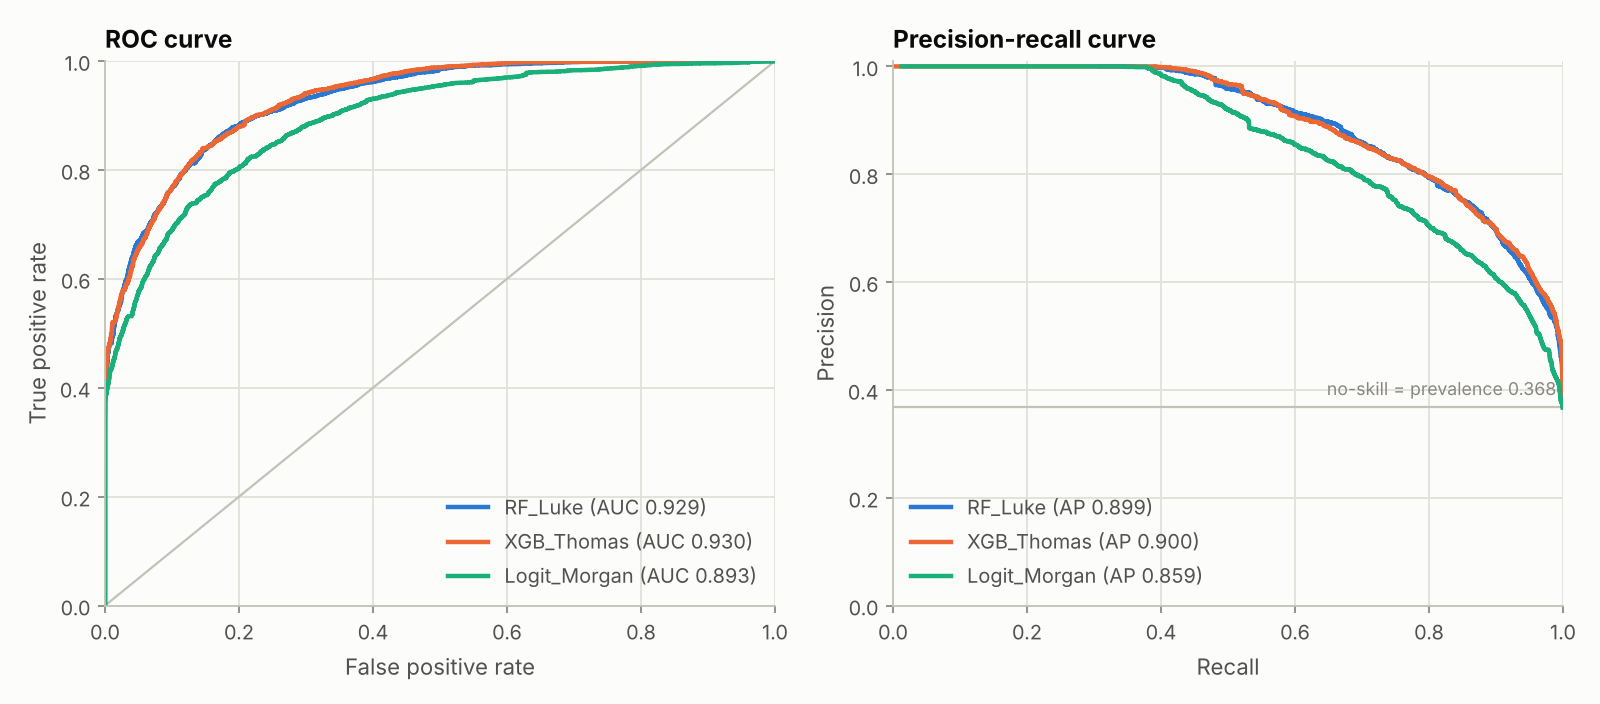

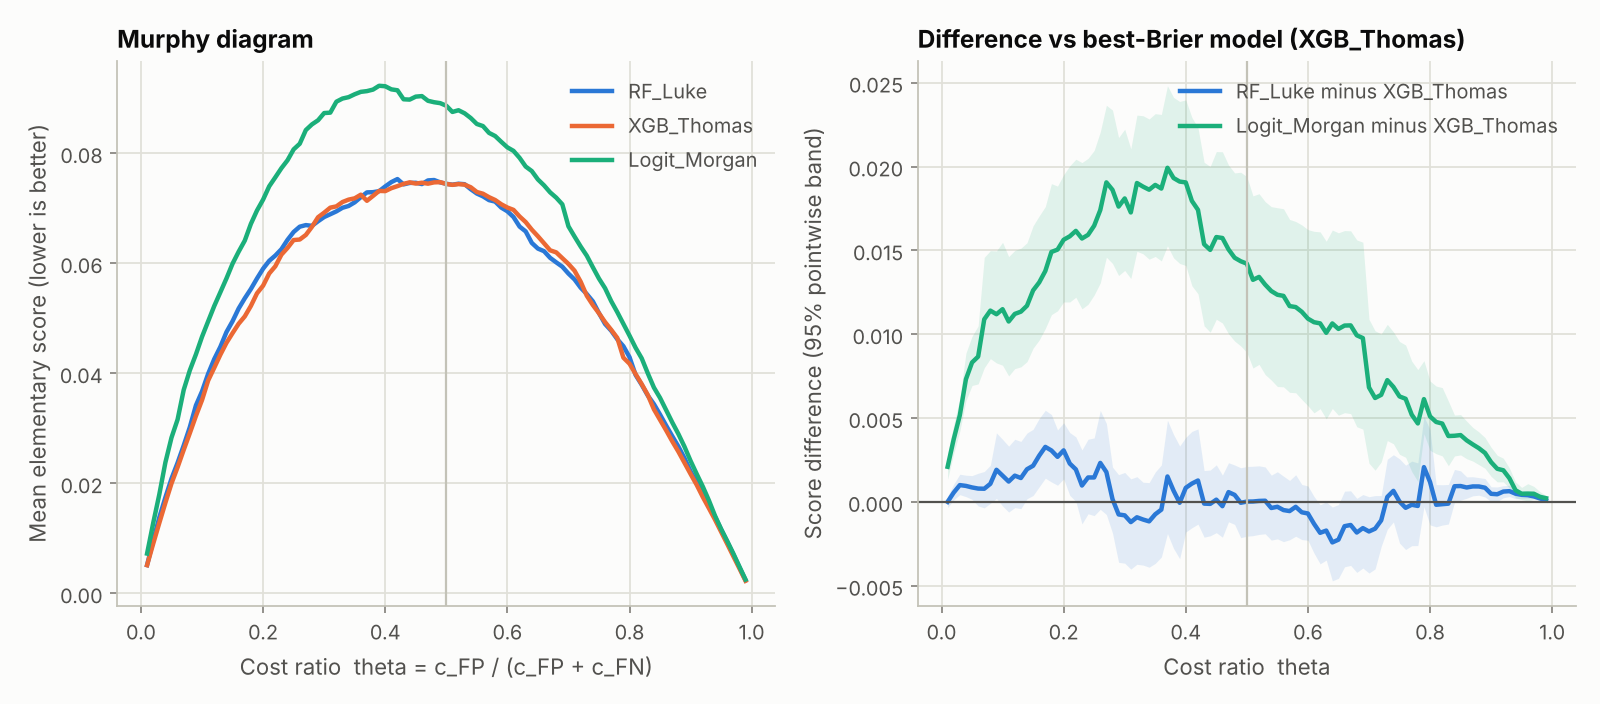

In [4]:
for f in ["reliability.png", "roc_pr.png", "murphy.png"]:
    display(Image(filename=os.path.join("eval", f), width=720))

The reliability diagram (top) shows the tree models close to the diagonal, while the logistic regression over-predicts for bookings it gives a probability above about 0.75. The ROC and precision-recall curves (middle) of the two tree models lie on top of each other, above the logistic regression's. On the Murphy diagram (bottom), which shows the expected cost for every ratio of false-positive to false-negative cost, the logistic regression is worse at every cost ratio, while the random forest and XGBoost cross several times.

The table gives the Brier score in each hotel and in two harder subsets: test bookings whose booking event (rooms booked together) never appears in the training or validation data, and bookings with no deposit, which excludes the non-refundable bookings that are almost always cancelled.

In [5]:
brier = lambda p, mask: np.mean((p[mask] - y[mask]) ** 2)
subsets = {"All test bookings": np.ones(len(y), bool),
           "Resort Hotel": truth.hotel.to_numpy() == "Resort Hotel",
           "City Hotel": truth.hotel.to_numpy() == "City Hotel",
           "Unseen booking events": truth.event_seen.to_numpy() == 0,
           "No Deposit bookings": clean.loc[truth.id, "deposit_type"].to_numpy() == "No Deposit"}
pd.DataFrame({name: {k: brier(p, mask) for k, mask in subsets.items()} for name, p in preds.items()}) \
  .assign(bookings=[int(mask.sum()) for mask in subsets.values()]).round(4)

,XGB_Thomas,RF_Luke,Logit_Morgan,bookings
All test bookings,0.1014,0.1021,0.1225,17903
Resort Hotel,0.0949,0.0969,0.1235,5785
City Hotel,0.1045,0.1046,0.1220,12118
Unseen booking events,0.1035,0.1038,0.1252,13450
No Deposit bookings,0.1157,0.1166,0.1398,15637


The order is the same in every row: XGBoost, then the random forest, then the logistic regression. The gap between the two tree models is never more than 0.002, while the logistic regression is 0.017 to 0.029 behind.

## 2. Strengths and weaknesses of each model

| | XGBoost | Random forest | Logistic regression |
| --- | --- | --- | --- |
| **Strengths** | Lowest Brier score and log loss; calibrated without recalibration; early stopping chooses the number of trees | Finds non-linear effects and interactions automatically; adding trees cannot overfit; well calibrated after recalibration | Coefficients can be read as effects on the odds of cancellation; fast to fit; terms can be tested with likelihood-ratio tests |
| **Weaknesses** | Many hyperparameters to tune; trees are fitted one after another, so it cannot be parallelised across trees; needs SHAP values to interpret | Slowest to fit; its out-of-bag estimate is misleading because of duplicate rows; too cautious at the resort hotel (calibration slope 1.14) | Non-linear effects and interactions must be chosen by hand (splines, hotel–price interaction); weakest discrimination (AUC 0.893); 187 parameters, so less interpretable than it first appears |

## 3. Conclusion

**Answer to our question.** Hotel cancellations can be predicted well from information available at booking. Both tree models rank bookings with an AUC of 0.93 and remove 56% of the Brier score of a constant forecast, against 47% for the logistic regression. Under our protocol, both tree models are better than the logistic regression, but neither tree model is better than the other: their Brier difference is not significant and they swap places on the Murphy diagram. Most of the logistic regression's gap comes from weaker discrimination rather than calibration, because the trees find interactions that the regression would need to be given by hand.

**Robustness.** The ranking of the logistic regression below the tree models holds in both hotels, on bookings from unseen booking events, without the non-refundable bookings, and at every cost ratio. The order of the two tree models does not hold in the same way: XGBoost is ahead in every subset, but by no more than 0.002, and the random forest has the lower cost at some cost ratios. The intervals use a cluster bootstrap, so the copies of identical bookings in the test set do not make them too narrow, and the metric, test set and definition of "best" were agreed before any model was scored.

**Limitations.**

* The random split tests each model on the same months and years it was trained on. When XGBoost was refitted on arrivals up to December 2016 and tested on 2017, its AUC fell from 0.930 to 0.885 and it under-predicted cancellations (`ThomasF/ThomasF_test.ipynb`). We did not run this check for the other models, so we cannot say how the ranking would change for future bookings.
* All three models rely heavily on `deposit_type`, because almost every non-refundable booking was cancelled. This may reflect how these two hotels recorded group bookings, and may not hold elsewhere.
* The Brier score weights every booking equally. A hotel's overbooking decision depends on prices and the cost of turning a guest away, which we did not have.
* The data come from two Portuguese hotels between 2015 and 2017.
* Each member tuned their own model in their own way, so some of the difference between models may reflect tuning effort rather than the type of model.